
LeetCode #42: Trapping Rain Water

• Difficulty Level: Hard
• The Problem Concept: Unlike Problem #11 (where you pick just two walls to form one huge pool), here the walls in the middle block and hold the water. 

You are calculating the total water trapped across the entire structural skyline.

Statement: Given n non-negative integers representing an elevation map where the width of each bar is 1, compute how much water it can trap after raining.

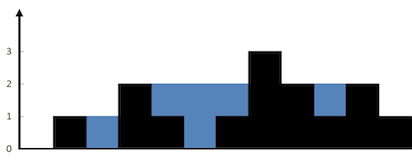

Input: height = [0,1,0,2,1,0,1,3,2,1,2,1]

Output: 6

Explanation: 

The above elevation map (black section) is represented by array 
[0,1,0,2,1,0,1,3,2,1,2,1]. 

In this case, 6 units of rain water (blue section) are being trapped.

Example 2:

Input: height = [4,2,0,3,2,5]
Output: 9

Constraints:

    n == height.length
    1 <= n <= 2 * 104
    0 <= height[i] <= 105



The Problem Concept: 

Unlike Problem #11 (where you pick just two walls to form one huge pool), here the walls in the middle block and hold the water. You are calculating the total water trapped across the entire structural skyline.


Method 1: The Naive Approach (Brute Force)

For every single bar in the array, you look all the way to its left to find the tallest wall, and all the way to its right to find the tallest wall. The water above that specific bar is bounded by the shorter of those two walls.


In [ ]:
def trap_naive(height):
    if not height:
        return 0
    
    total_water = 0
    n = len(height)
    
    # Check every element except the first and last (as edges can't trap water)
    for i in range(1, n - 1):
        # 1. Find the maximum height to the left of i
        max_left = max(height[:i+1])
        
        # 2. Find the maximum height to the right of i
        max_right = max(height[i:])
        
        # 3. Water trapped = min(max_left, max_right) - current height
        total_water += min(max_left, max_right) - height[i]
        
    return total_water


• Time Complexity: O(N^2) because for each of the N bars, you perform two scans looking left and right. This will result in a Time Limit Exceeded (TLE) error on LeetCode.
• Space Complexity: O(1) constant space.



Method 2: Dynamic Programming (Precomputing Maximums)

Instead of looking left and right repeatedly, we can scan the array twice beforehand to pre-calculate the boundaries and save them in two auxiliary arrays.

In [ ]:
def trap_dp(height):
    if not height:
        return 0
        
    n = len(height)
    left_max = [0] * n
    right_max = [0] * n
    total_water = 0
    
    # Fill left_max array (Left to Right scan)
    left_max[0] = height[0]
    for i in range(1, n):
        left_max[i] = max(left_max[i-1], height[i])
        
    # Fill right_max array (Right to Left scan)
    right_max[n-1] = height[n-1]
    for i in range(n-2, -1, -1):
        right_max[i] = max(right_max[i+1], height[i])
        
    # Calculate water trapped at each index
    for i in range(n):
        total_water += min(left_max[i], right_max[i]) - height[i]
        
    return total_water



• Time Complexity: O(N) because we complete three linear sweeps.
• Space Complexity: O(N) extra memory to maintain the left_max and right_max tracking lists.


Method 3: The Optimal Two-Pointer Strategy

We can optimize the space to O(1) by utilizing two pointers (left and right) moving toward the middle, along with two running variables (left_max and right_max). 

Because the water volume is consistently bottlenecked by the smaller structural boundary, we can safely advance whichever pointer faces the shorter overall maximum wall.

In [ ]:
def trap_optimal(height):
    if not height:
        return 0
        
    left, right = 0, len(height) - 1
    left_max, right_max = height[left], height[right]
    total_water = 0
    
    while left < right:
        if left_max < right_max:
            left += 1
            left_max = max(left_max, height[left])
            total_water += left_max - height[left]
        else:
            right -= 1
            right_max = max(right_max, height[right])
            total_water += right_max - height[right]
            
    return total_water

# --- Verification ---
heights = [0, 1, 0, 2, 1, 0, 1, 3, 2, 1, 2, 1]
print(trap_optimal(heights))  # Output: 6


• Time Complexity: O(N) (Single-pass search).
• Space Complexity: O(1) absolute constant space.

**Method 4: The Monotonic Stack Approach**

Another highly respected interview approach uses a Stack to keep track of bars in a decreasing height order. When you encounter a bar that is taller than the bar at the top of your stack, it means you have found a right wall that can trap water with a previous left wall. You pop the index from the stack, compute the water between them, and repeat.

• Time Complexity: O(N) (Each index is pushed and popped at most once).
• Space Complexity: O(N) to store indices in the stack frame.

Here, instead of processing the water column-by-column vertically, a monotonic stack allows you to calculate the water horizontally, layer-by-layer (like filling up steps of a valley).


The Core Intuition

To trap water, you need a valley shape: a low bar trapped between a left wall and a right wall.

1. We maintain a stack that stores indices of the bars in a strictly decreasing height order. As long as the bars keep getting shorter or stay the same height, no water can be trapped. We just push their indices onto the stack.

2. The moment we encounter a bar that is taller than the bar at the top of our stack, we have discovered a right wall!

3. We pop the low middle bar from the stack (this is our valley floor).

4. The new top of the stack becomes our left wall.

5. We calculate the water trapped in that horizontal block and add it to our total. We repeat this until the stack is decreasing again.


The Horizontal Water Formula

Every time we find a valid valley (Left Wall → Middle Valley → Right Wall), the horizontal water bounded between them is:

    Width = Right Index - Left Index - 1

    Bounded Height = min(Height[Left], Height[right]) - Height[middle]

    Water Trapped = Width * Bounded Height


In [ ]:
def trap_stack(height):
    if not height:
        return 0
        
    stack = []  # Stores indices of the bars
    total_water = 0
    current = 0  # Our right-wall scanner pointer
    
    while current < len(height):
        # While the stack is not empty AND the current bar is taller than the top of the stack
        while stack and height[current] > height[stack[-1]]:
            # 1. Pop the middle floor (the valley bottom)
            top_mid = stack.pop()
            
            # If the stack becomes empty, there is no left wall. No water can be trapped.
            if not stack:
                break
                
            # 2. The new top of the stack is our left wall
            left_wall_idx = stack[-1]
            
            # 3. Calculate bounded limits
            width = current - left_wall_idx - 1
            bounded_height = min(height[left_wall_idx], height[current]) - height[top_mid]
            
            # 4. Accumulate the horizontal layer of water
            total_water += width * bounded_height
            
        # Push the current index onto the stack
        stack.append(current)
        current += 1
        
    return total_water

# --- Verification ---
heights = [0, 1, 0, 2, 1, 0, 1, 3, 2, 1, 2, 1]
print(trap_stack(heights))  # Output: 6



Complexity Analysis

• Time Complexity: O(N). Even though there is a nested while loop, every single index is pushed onto the stack exactly once and popped from the stack at most once. This amortizes to absolute linear time.

• Space Complexity: O(N) in the worst-case scenario where the array structure is strictly decreasing (e.g., [5, 4, 3, 2, 1]), causing all elements to sit inside the stack frame simultaneously.
